In [2]:
from google.colab import files
uploaded = files.upload()


Saving motor_condition_dataset_cleaned (1).csv to motor_condition_dataset_cleaned (1).csv


Shape: (6000, 8)
       Irms        Ax        Ay        Az  Label  vibration_mag  \
0  0.746219  9.060197  2.566290  2.996932      3       9.882035   
1  0.253052  9.801291  0.110097  1.310059      1       9.889069   
2  0.220342  9.788470  0.080646  1.243287      0       9.867442   
3  0.886306  9.772801  0.558601  1.336835      2       9.879616   
4  0.797372  9.712460 -0.708281  0.343204      3       9.744297   

   vibration_delta  vibration_std  
0         0.082035       0.000000  
1         0.089069       0.000000  
2         0.067442       0.000000  
3         0.079616       0.000000  
4        -0.055703       0.060984  

Columns: ['Irms', 'Ax', 'Ay', 'Az', 'Label', 'vibration_mag', 'vibration_delta', 'vibration_std']

Missing values:
 Irms               0
Ax                 0
Ay                 0
Az                 0
Label              0
vibration_mag      0
vibration_delta    0
vibration_std      0
dtype: int64

Label distribution:
 Label
0    1500
1    1500
2    1500
3    150

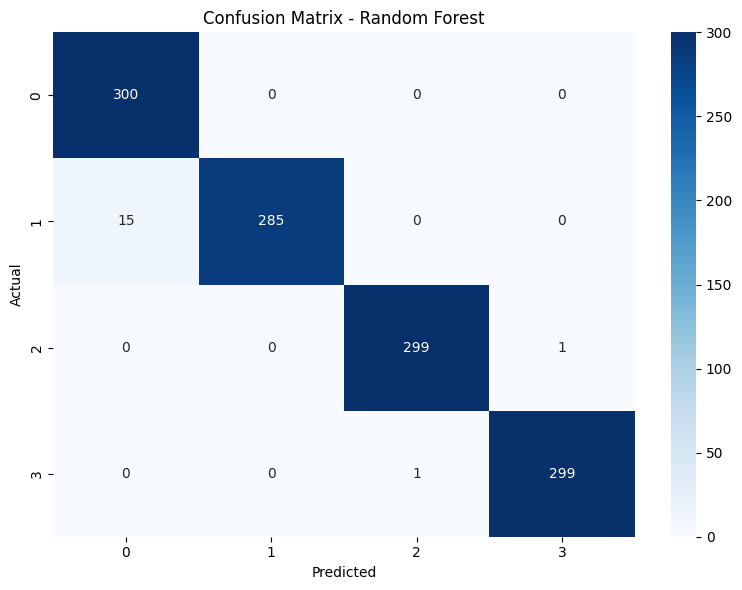

              precision    recall  f1-score   support

           0     0.9172    0.9967    0.9553       300
           1     0.9891    0.9100    0.9479       300
           2     0.9771    0.9967    0.9868       300
           3     1.0000    0.9733    0.9865       300

    accuracy                         0.9692      1200
   macro avg     0.9709    0.9692    0.9691      1200
weighted avg     0.9709    0.9692    0.9691      1200


Files saved:
- model_comparison.csv
- classification_report.csv
- confusion_matrix.csv
- scaler.pkl
- best_model.pkl


In [4]:
# Google Colab Notebook: Motor Condition Classification

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline
import joblib

# =====================
# 1. Load Dataset
# =====================
# If using Colab, upload the CSV first or mount Google Drive.
# Example upload code:
# from google.colab import files
# uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

# If the file is already in the working directory:
# df = pd.read_csv('motor_condition_dataset_cleaned.csv')

print('Shape:', df.shape)
print(df.head())
print('\nColumns:', df.columns.tolist())
print('\nMissing values:\n', df.isna().sum())
print('\nLabel distribution:\n', df['Label'].value_counts().sort_index())

# =====================
# 2. Prepare Data
# =====================
X = df.drop(columns=['Label'])
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =====================
# 3. Train Models
# =====================
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced'
    ),
    'SVM': SVC(
        kernel='rbf',
        C=10,
        gamma='scale'
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    results.append({'Model': name, 'Accuracy': acc, 'F1 Macro': f1})
    trained_models[name] = preds

results_df = pd.DataFrame(results).sort_values(by='F1 Macro', ascending=False)
print('\nModel Comparison:\n')
print(results_df)

# =====================
# 4. Best Model Evaluation
# =====================
best_model_name = results_df.iloc[0]['Model']
best_preds = trained_models[best_model_name]

print('\nBest Model:', best_model_name)
print('\nClassification Report:\n')
print(classification_report(y_test, best_preds))

cm = confusion_matrix(y_test, best_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

svm_model = make_pipeline(StandardScaler(), SVC())
svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)
print(classification_report(y_test, svm_pred, digits=4))

# =====================
# 5. Save Outputs
# =====================
results_df.to_csv('model_comparison.csv', index=False)

report = classification_report(y_test, best_preds, output_dict=True)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv('classification_report.csv')

cm_df = pd.DataFrame(cm)
cm_df.to_csv('confusion_matrix.csv', index=False)

joblib.dump(scaler, 'scaler.pkl')
joblib.dump(models[best_model_name], 'best_model.pkl')

print('\nFiles saved:')
print('- model_comparison.csv')
print('- classification_report.csv')
print('- confusion_matrix.csv')
print('- scaler.pkl')
print('- best_model.pkl')


In [5]:
from google.colab import drive
drive.mount('/content/drive')

joblib.dump(scaler, '/content/drive/MyDrive/scaler.pkl')
joblib.dump(models[best_model_name], '/content/drive/MyDrive/best_model.pkl')
results_df.to_csv('/content/drive/MyDrive/model_comparison.csv', index=False)
report_df.to_csv('/content/drive/MyDrive/classification_report.csv')
cm_df.to_csv('/content/drive/MyDrive/confusion_matrix.csv', index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
